# What is an AnnData object?

**AnnData** ("annotated data") is the standard in-memory container for single-cell data in Python (used by [scanpy](https://scanpy.readthedocs.io), squidpy, scvi-tools, ...). It bundles one main data matrix together with all the metadata that stays *aligned* to it.

This notebook walks through **every slot** of an AnnData object, grounded in a real dataset (**PBMC 3k** — 2,700 peripheral-blood immune cells from 10x Genomics). Skim it in 5–10 minutes and you'll know what each slot holds and why.

## 1. The overall model

An AnnData is built around a matrix `X` of shape **`n_obs` × `n_vars`** — rows are **observations** (cells), columns are **variables** (genes). Everything else is annotation that stays aligned to those rows and columns:

```
                          var  (per-GENE metadata, one row per column of X)
                     ┌────────────────────────────┐
                     │  gene_0  gene_1  ...  gene_G  │
        ┌────────┐  ┌──┼──────────────────────────┐    ┐
        │ cell_0 │  │              X               │    │  obsm  (per-cell arrays:
  obs   │ cell_1 │  │   n_obs × n_vars data matrix  │    │         X_pca, X_umap)
(per-   │  ...   │  │   (dense or sparse CSR)      │    │  layers (same shape as X:
 CELL)  │ cell_N │  │                              │    │         counts, ...)
        └────────┘  └────────────────────────────┘    ┘
                        varm (per-gene arrays: PCs)

  obsp : cell × cell graphs (neighbors)      uns : unstructured dict (params,
  varp : gene × gene graphs                          palettes, run metadata)
  raw  : frozen snapshot of X + var before filtering/normalization
```

The key invariant: **anything indexed by cells has `n_obs` rows; anything indexed by genes has `n_vars` rows.** Slice the AnnData and all aligned pieces slice together.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd

# Load the real dataset straight from disk.
adata = ad.read_h5ad("data/pbmc3k_modern.h5ad")
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

Right off disk this file is **raw**: it has only `X` (the count matrix) and one `var` column (`gene_ids`). All the other slots — `obs`, `obsm`, `layers`, ... — are empty. That is completely normal: those slots get **filled in as you analyze the data**.

So we run a standard scanpy pipeline once, below, to populate every slot with *real* values. Then the rest of the notebook inspects each slot on this processed object.

In [2]:
# --- Standard scanpy preprocessing, purely so every slot gets populated ---
adata.layers["counts"] = adata.X.copy()            # keep raw counts in a layer
sc.pp.filter_genes(adata, min_cells=3)             # drop genes seen in <3 cells
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True, percent_top=None)
sc.pp.normalize_total(adata, target_sum=1e4)       # library-size normalize
sc.pp.log1p(adata)                                 # log(1+x)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
adata.raw = adata                                  # freeze a snapshot
sc.pp.pca(adata, n_comps=30)                       # -> obsm['X_pca'], varm['PCs']
sc.pp.neighbors(adata, n_neighbors=10)             # -> obsp graphs
sc.tl.umap(adata)                                  # -> obsm['X_umap']

# A categorical cell grouping (like a cell-type label) via k-means on the PCA.
from sklearn.cluster import KMeans
labels = KMeans(n_clusters=8, random_state=0, n_init=10).fit_predict(adata.obsm["X_pca"])
adata.obs["cell_type"] = pd.Categorical([f"group_{i}" for i in labels])

adata

AnnData object with n_obs × n_vars = 2700 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'cell_type'
    var: 'gene_ids', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

Now every slot is filled. Notice `n_vars` dropped from 32,738 to ~13,714 (gene filtering). The printed summary above lists the keys living in each slot — we'll go through them one at a time.

## 2. `X` — the main data matrix

`X` is the cells × genes matrix at the center. Each entry is the expression of one gene in one cell. Because most genes are undetected in most cells, `X` is usually stored **sparse** (scipy CSR) to save memory.

The *values* depend on where you are in the pipeline: raw integer **counts** early on, then **library-normalized** and **log-transformed** floats after preprocessing (what we have now). The matrix itself doesn't record which — that's a convention you track yourself (and often stash the counts in a layer, as we did).

In [3]:
import scipy.sparse as sp
print("type :", type(adata.X).__name__, "| sparse:", sp.issparse(adata.X))
print("shape:", adata.X.shape, "(n_obs × n_vars)")
print("dtype:", adata.X.dtype)
print("stored (nonzero) fraction: {:.1%}".format(adata.X.nnz / (adata.n_obs * adata.n_vars)))
print("value range: {:.2f} .. {:.2f}  (log-normalized)".format(adata.X.min(), adata.X.max()))
# a tiny dense corner: first 3 cells x 4 genes
print("\ncorner (3 cells x 4 genes):\n", adata.X[:3, :4].toarray())

type : csr_matrix | sparse: True
shape: (2700, 13714) (n_obs × n_vars)
dtype: float32
stored (nonzero) fraction: 6.2%
value range: 0.00 .. 7.47  (log-normalized)

corner (3 cells x 4 genes):
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


## 3. `obs` — per-cell metadata

`obs` is a **pandas DataFrame with one row per cell** (`obs.index` = cell barcodes, aligned to the rows of `X`). Columns hold anything you know per cell: QC metrics (`total_counts`, `pct_counts_mt`), sample/batch IDs, and cluster / cell-type labels.

Label-like columns are typically **categorical** (memory-efficient, fixed set of levels). `obs` is what you filter on (`adata[adata.obs.pct_counts_mt < 5]`), group by, and color plots by.

In [4]:
print("obs shape:", adata.obs.shape, " index name:", adata.obs.index.name)
print("barcodes:", list(adata.obs.index[:3]), "...\n")
print(adata.obs.dtypes, "\n")
print(adata.obs[["total_counts", "pct_counts_mt", "cell_type"]].head())
print("\ncell_type is categorical:", adata.obs["cell_type"].cat.categories.tolist())
print("\ncounts per group:\n", adata.obs["cell_type"].value_counts())

obs shape: (2700, 8)  index name: index
barcodes: ['AAACATACAACCAC-1', 'AAACATTGAGCTAC-1', 'AAACATTGATCAGC-1'] ...

n_genes_by_counts             int32
log1p_n_genes_by_counts     float64
total_counts                float32
log1p_total_counts          float32
total_counts_mt             float32
log1p_total_counts_mt       float32
pct_counts_mt               float32
cell_type                  category
dtype: object 

                  total_counts  pct_counts_mt cell_type
index                                                  
AAACATACAACCAC-1        2419.0       3.017776   group_0
AAACATTGAGCTAC-1        4903.0       3.793596   group_3
AAACATTGATCAGC-1        3147.0       0.889736   group_5
AAACCGTGCTTCCG-1        2639.0       1.743085   group_7
AAACCGTGTATGCG-1         980.0       1.224490   group_4

cell_type is categorical: ['group_0', 'group_1', 'group_2', 'group_3', 'group_4', 'group_5', 'group_6', 'group_7']

counts per group:
 cell_type
group_0    622
group_5    542
group_1    4

## 4. `var` — per-gene metadata

The column-side mirror of `obs`: a DataFrame with **one row per gene** (`var.index` = gene symbols, aligned to the columns of `X`). It holds gene IDs, per-gene QC (`n_cells_by_counts`, `mean_counts`), and flags such as `highly_variable` that downstream steps (PCA) use to subset genes.

In [5]:
print("var shape:", adata.var.shape, " index name:", adata.var.index.name)
print("gene symbols:", list(adata.var.index[:5]), "...\n")
print(adata.var[["gene_ids", "n_cells_by_counts", "mean_counts", "highly_variable"]].head())
print("\nhighly-variable genes flagged:", int(adata.var["highly_variable"].sum()))

var shape: (13714, 13)  index name: index
gene symbols: ['AL627309.1', 'AP006222.2', 'RP11-206L10.2', 'RP11-206L10.9', 'LINC00115'] ...

                      gene_ids  n_cells_by_counts  mean_counts  \
index                                                            
AL627309.1     ENSG00000237683                  9     0.003333   
AP006222.2     ENSG00000228463                  3     0.001111   
RP11-206L10.2  ENSG00000228327                  5     0.001852   
RP11-206L10.9  ENSG00000237491                  3     0.001111   
LINC00115      ENSG00000225880                 18     0.006667   

               highly_variable  
index                           
AL627309.1               False  
AP006222.2               False  
RP11-206L10.2            False  
RP11-206L10.9            False  
LINC00115                False  

highly-variable genes flagged: 2000


## 5. `obsm` — per-cell multi-dimensional arrays

`obsm` ("obs matrices") stores arrays with **`n_obs` rows and any number of columns** — one *vector per cell*. This is where **embeddings** live: `X_pca` (n_obs × n_components) and `X_umap` (n_obs × 2). Neighbor graphs are built on `X_pca`; 2-D `X_umap` is what scatter plots draw.

In [6]:
for k in adata.obsm:
    print(f"{k:8s} shape {adata.obsm[k].shape}  dtype {adata.obsm[k].dtype}")
print("\nX_umap coords for first 3 cells:\n", adata.obsm["X_umap"][:3])

X_pca    shape (2700, 30)  dtype float32
X_umap   shape (2700, 2)  dtype float32

X_umap coords for first 3 cells:
 [[-2.7330875  0.677769 ]
 [-0.4362723  9.229124 ]
 [-1.163445   4.158149 ]]


## 6. `varm` — per-gene multi-dimensional arrays

The gene-side analogue of `obsm`: arrays with **`n_vars` rows**. The classic entry is `PCs` — the PCA **loadings**, i.e. how much each gene contributes to each principal component (n_vars × n_components). Together, `X_pca = X_centered @ PCs`.

In [7]:
print("varm['PCs'] shape:", adata.varm["PCs"].shape, "(n_vars × n_components)")
# top genes driving principal component 1
pc1 = pd.Series(adata.varm["PCs"][:, 0], index=adata.var_names)
print("\ntop genes loading on PC1:\n", pc1.abs().sort_values(ascending=False).head())

varm['PCs'] shape: (13714, 30) (n_vars × n_components)

top genes loading on PC1:
 index
LYZ       0.238273
S100A9    0.229282
CST3      0.227323
TYROBP    0.212839
S100A8    0.188501
dtype: float64


## 7. `layers` — alternative matrices, same shape as `X`

Each layer is a full **`n_obs` × `n_vars`** matrix living beside `X`. Use them to keep multiple representations of the same cells × genes: raw `counts` (we saved these before normalizing), or `spliced`/`unspliced` for RNA velocity. `X` is your "current working" matrix; layers are the alternates you can always fall back to.

In [8]:
print("layers:", list(adata.layers.keys()))
print("counts shape:", adata.layers["counts"].shape, "== X shape:", adata.X.shape)
print("\ncounts layer (raw integers)   :", adata.layers["counts"][:3, :4].toarray().tolist())
print("X          (log-normalized)   :", np.round(adata.X[:3, :4].toarray(), 2).tolist())

layers: ['counts']
counts shape: (2700, 13714) == X shape: (2700, 13714)

counts layer (raw integers)   : [[0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]]
X          (log-normalized)   : [[0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]]


## 8. `obsp` / `varp` — pairwise graphs

`obsp` ("obs pairwise") holds **`n_obs` × `n_obs`** matrices — relationships between *pairs of cells*. `sc.pp.neighbors` writes two sparse graphs here: `distances` (k-nearest-neighbor distances) and `connectivities` (weighted graph). These drive UMAP, clustering, and trajectory inference. `varp` is the same idea for gene × gene relationships (e.g. co-expression networks); it's empty here, which is typical.

In [9]:
for k in adata.obsp:
    m = adata.obsp[k]
    print(f"obsp['{k}'] shape {m.shape}  sparse={sp.issparse(m)}  ~{m.nnz/adata.n_obs:.1f} edges/cell")
print("\nvarp keys:", list(adata.varp.keys()), "(empty here — no gene-gene graph computed)")

obsp['distances'] shape (2700, 2700)  sparse=True  ~9.0 edges/cell
obsp['connectivities'] shape (2700, 2700)  sparse=True  ~14.4 edges/cell

varp keys: [] (empty here — no gene-gene graph computed)


## 9. `uns` — unstructured metadata

`uns` is a free-form **dictionary** for anything that isn't aligned to cells or genes: parameters of the runs (`pca`, `neighbors`, `umap` settings), color **palettes** for categorical `obs` columns (e.g. `cell_type_colors`), and general run metadata. Tools read/write it to remember how results were produced.

uns keys: ['log1p', 'hvg', 'pca', 'neighbors', 'umap']

neighbors params: {'n_neighbors': 10, 'method': 'umap', 'random_state': 0, 'metric': 'euclidean'}
pca variance_ratio (first 5): [0.101 0.036 0.024 0.011 0.007]

cell_type_colors: ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']


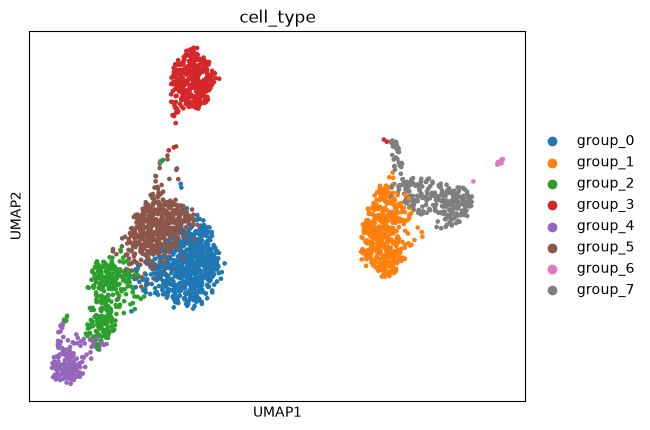

In [10]:
print("uns keys:", list(adata.uns.keys()))
print("\nneighbors params:", adata.uns["neighbors"]["params"])
print("pca variance_ratio (first 5):", np.round(adata.uns["pca"]["variance_ratio"][:5], 3))
# scanpy stores a color palette in uns the first time you plot a categorical column
sc.pl.umap(adata, color="cell_type", show=False)
print("\ncell_type_colors:", adata.uns["cell_type_colors"])

## 10. `raw` — a frozen snapshot

`adata.raw` stores a **read-only copy of `X` and `var`** from an earlier point (we set it right after normalization, before subsetting to highly-variable genes). It keeps the *full gene set* around so you can still look up or plot any gene after `adata` itself has been filtered down. Common pattern: cluster on HVGs in `adata`, but pull marker-gene expression from `adata.raw`.

In [11]:
print("adata.raw is set:", adata.raw is not None)
print("raw n_vars:", adata.raw.n_vars, " vs current n_vars:", adata.n_vars)
print("(here they match; if we subset adata to HVGs, raw would keep all genes)")
# raw is read-only and aligned to the same cells
print("raw.X shape:", adata.raw.X.shape)

adata.raw is set: True
raw n_vars: 13714  vs current n_vars: 13714
(here they match; if we subset adata to HVGs, raw would keep all genes)
raw.X shape: (2700, 13714)


## 11. How it's persisted on disk

`.h5ad` is just an **HDF5** file (there's an equivalent **Zarr** form, `.zarr`). AnnData maps each slot to a group/dataset and tags it with an `encoding-type` attribute so it can be read back into the right Python object: `dataframe` for `obs`/`var`, `csr_matrix` for sparse `X`, `categorical` for label columns, plain arrays for `obsm`/`varm`.

This matters for **byte-range virtualization** (what this repo does): numeric arrays are stored as regular contiguous/chunked HDF5 datasets, so a client can fetch just the bytes it needs over HTTP — but variable-length strings (e.g. categorical *categories*) use HDF5 vlen storage, which isn't directly byte-range addressable. Let's peek at the raw HDF5 attributes.

In [12]:
import tempfile, os, h5py
tmp = os.path.join(tempfile.mkdtemp(), "demo.h5ad")
adata.write_h5ad(tmp)

with h5py.File(tmp, "r") as f:
    print("top-level groups:", list(f.keys()), "\n")
    for path in ["X", "obs", "var", "obsm/X_pca", "layers/counts", "obs/cell_type"]:
        et = f[path].attrs.get("encoding-type", "(none)")
        print(f"{path:16s} encoding-type = {et}")
os.remove(tmp)

top-level groups: ['X', 'layers', 'obs', 'obsm', 'obsp', 'raw', 'uns', 'var', 'varm', 'varp'] 

X                encoding-type = csr_matrix
obs              encoding-type = dataframe
var              encoding-type = dataframe
obsm/X_pca       encoding-type = array
layers/counts    encoding-type = csr_matrix
obs/cell_type    encoding-type = categorical


## Recap

| slot | shape / type | holds |
|------|-------------|-------|
| `X` | n_obs × n_vars (sparse/dense) | the main expression matrix |
| `obs` | DataFrame, n_obs rows | per-cell metadata (QC, labels) |
| `var` | DataFrame, n_vars rows | per-gene metadata (IDs, HVG flags) |
| `obsm` | n_obs × k arrays | per-cell embeddings (`X_pca`, `X_umap`) |
| `varm` | n_vars × k arrays | per-gene arrays (PC loadings) |
| `layers` | n_obs × n_vars each | alternate matrices (raw `counts`) |
| `obsp` / `varp` | n_obs² / n_vars² | pairwise graphs (neighbors) |
| `uns` | dict | params, palettes, run metadata |
| `raw` | frozen AnnData | pre-filter snapshot of `X` + `var` |

The one rule that ties it together: **rows align to cells, columns align to genes**, so slicing an AnnData keeps every annotation consistent.